# PINN 1D · 瞬态非线性 Burgers

主线一覆盖瞬态非线性物理。求解

$$u_t + u u_x - \nu u_{xx}=0,\quad x\in[-1,1],\ t\in[0,1],\quad \nu=0.01/\pi,$$

初值为 $u(x,0)=-\sin(\pi x)$，边界为 $u(-1,t)=u(1,t)=0$。内部、初值和边界
配点共同进入 PINN loss。已提交的演示结果为 **3000** 步、相对 L2 约 **0.041**
（Cole–Hopf 参考）。下面的固定随机种子 12 步 CPU **smoke** 只检查链路，
不是该演示数字。

In [1]:
from pathlib import Path
import json

import openpinn as op

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
print("OpenPINN", op.__version__, "| CPU smoke | repo", ROOT.name)


OpenPINN 0.2.0 | CPU smoke | repo OpenPINN-upstream


## 训练：PDE + IC + BC 配点

In [2]:
result = op.solve(
    "burgers", method="baseline", steps=12, seed=0, device="cpu",
    model={"hidden_layers": [24, 24]},
    sampling={"interior": 32, "boundary": 8, "initial": 8},
    overrides={"evaluation": {"points": {"space": 21, "time": 9}}},
    output_dir=Path("/tmp/openpinn-m18-pinn-burgers"), plot=False,
)
print(json.dumps({key: result.metrics[key] for key in (
    "final_total_loss", "pde_residual_rmse", "initial_rmse", "relative_l2_error"
)}, indent=2))

step=1 total=2.945345e-01
step=2 total=5.103281e-01
step=3 total=5.214707e-01
step=4 total=5.438071e-01
step=5 total=4.886230e-01
step=6 total=4.996610e-01
step=7 total=3.572167e-01
step=8 total=4.870315e-01
step=9 total=2.553116e-01
step=10 total=5.034534e-01
step=11 total=2.265881e-01
step=12 total=4.446260e-01
{
  "final_total_loss": 0.44462600350379944,
  "pde_residual_rmse": 0.0849996954202652,
  "initial_rmse": 0.592356264591217,
  "relative_l2_error": 0.8746014833450317
}


## Smoke 指标

固定种子 12 步 CPU **smoke** 只检查调用链路，不是演示数字。损失和误差已打印在上面的训练输出中。本页不再绘制 smoke 损失曲线或时空对比。演示图见下一节，文件在 `examples/tutorials/artifacts/m19/burgers/`。


## 已提交的演示结果

下图来自维护者演示训练，文件在 `examples/tutorials/artifacts/m19/burgers/`。相对 L2 约 **0.041**（3000 步，Cole–Hopf 参考）。上面的 CPU **smoke** 只检查调用链路。


demo stop_steps=3000 relative_l2_error=0.041313 passed=True | Cole-Hopf reference


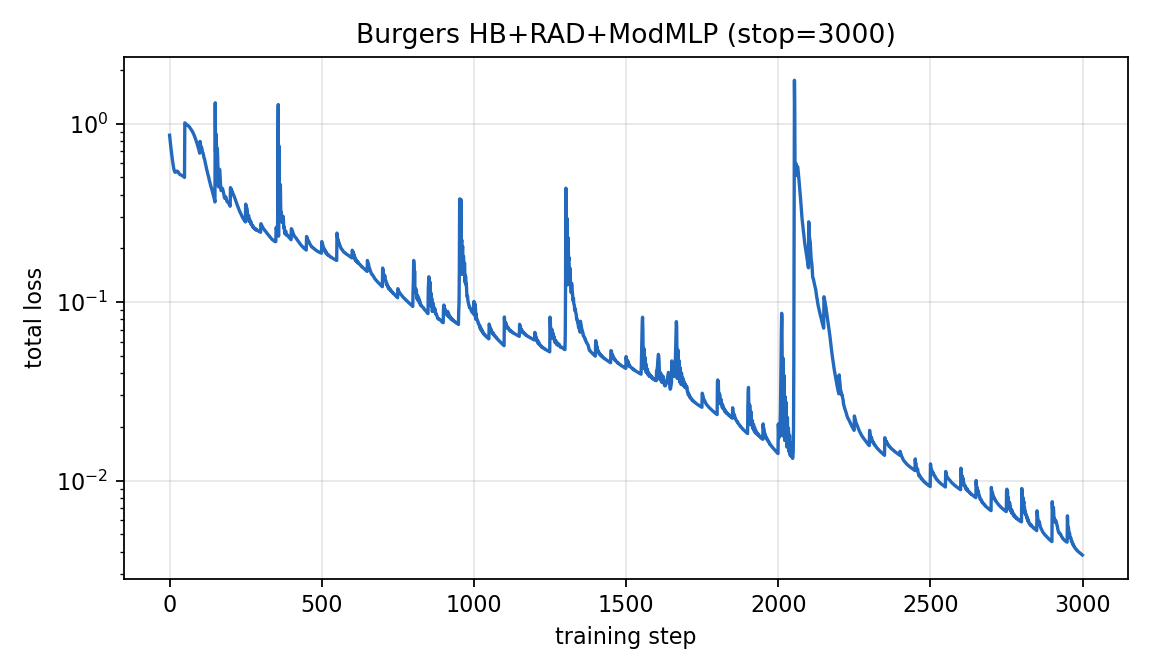

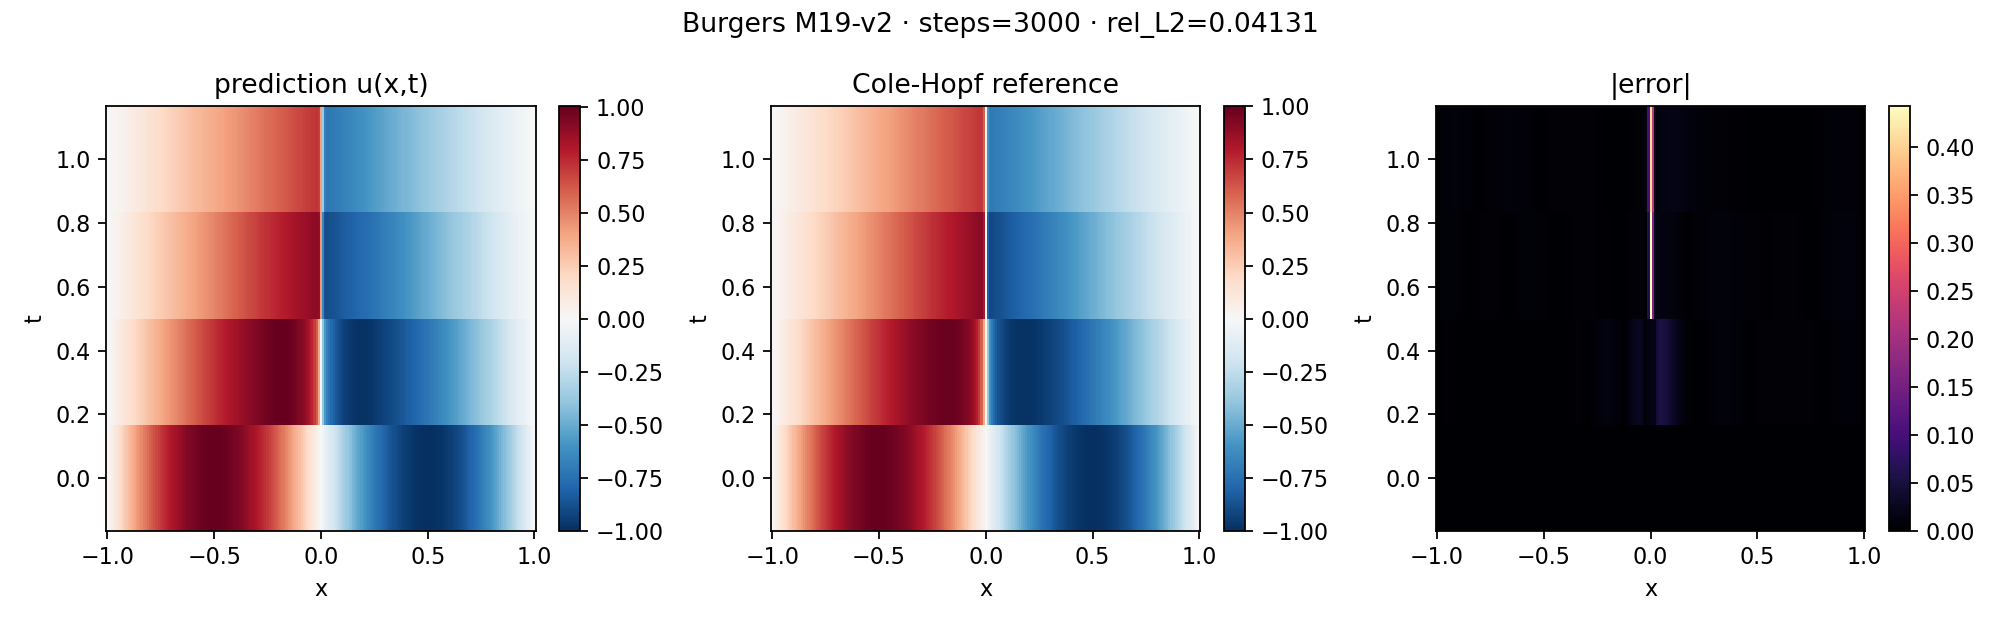

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
art = ROOT / "examples/tutorials/artifacts/m19/burgers"
metrics = json.loads((art / "metrics.json").read_text(encoding="utf-8"))
print(
    f"demo stop_steps={metrics['stop_steps']} "
    f"relative_l2_error={metrics['relative_l2_error']:.6f} "
    f"passed={metrics['passed']} | Cole-Hopf reference"
)
display(Image(filename=str(art / "loss.png")))
display(Image(filename=str(art / "solution_xt.png")))
